<a href="https://colab.research.google.com/github/NeriZadquielJaramilloMartinez/probabilidad/blob/main/Unidad6/CDAPPCEIEE_puntos_3y4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Número de casos positivos es : 4
Número de casos negativos: 17
Número de casos pendientes: 1111830

Número d pacientes ambulatorios: 894424
Número de pacientes hospitalizados: 217428

Número de pacientes embarazadas: 8273
Número de pacientes indígenas: 15500





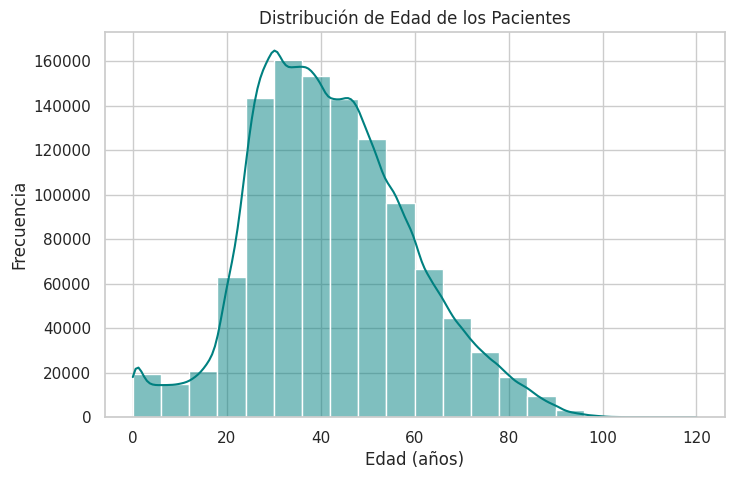

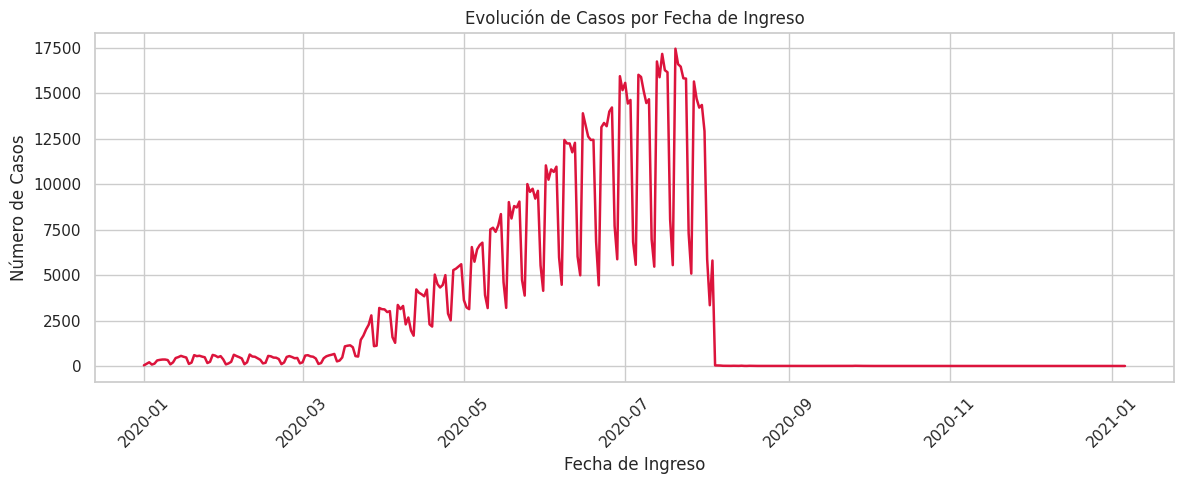

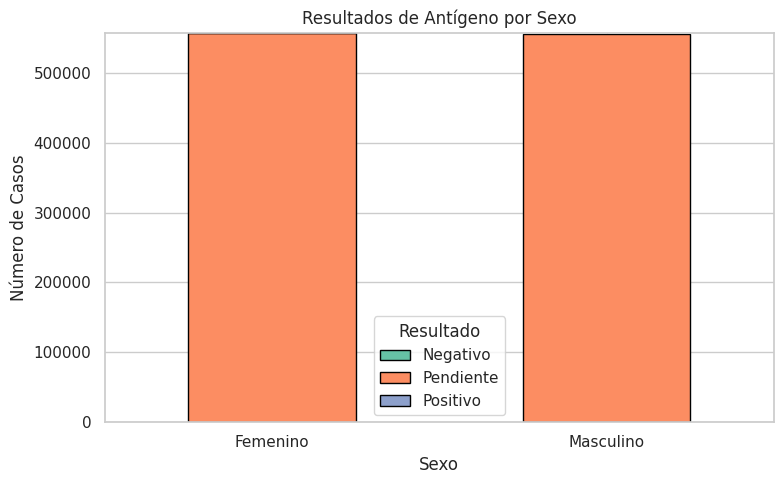

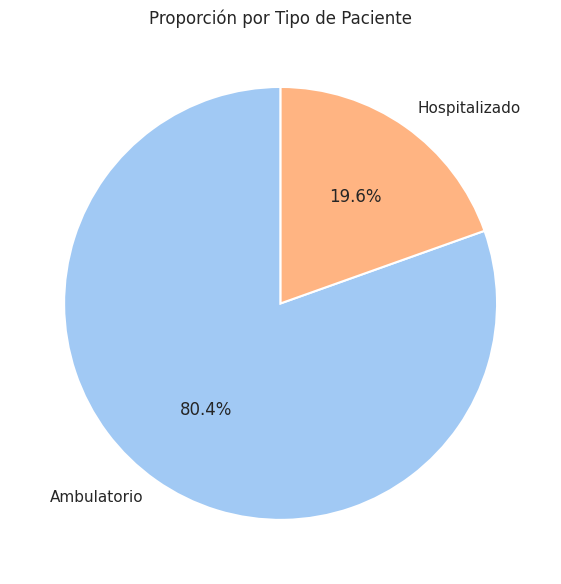

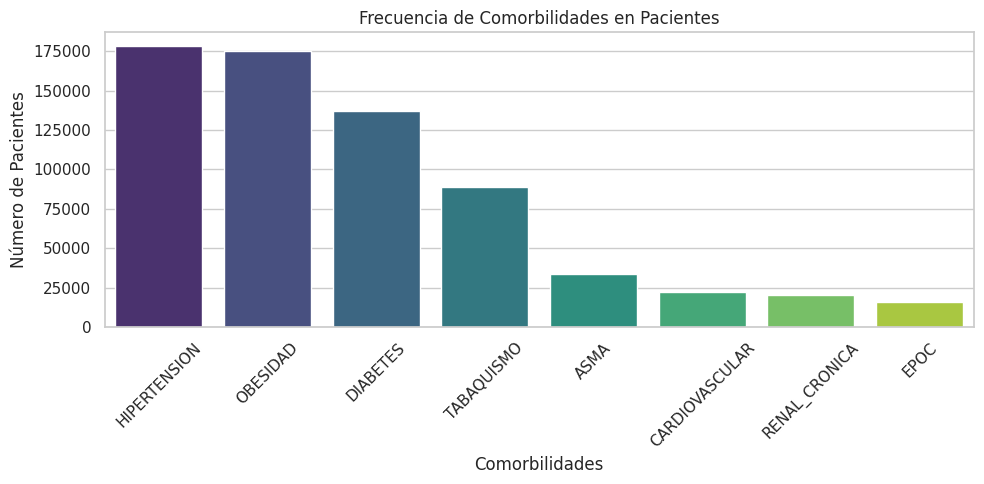

Total general de registros: 1111852

--- PROBABILIDAD SIMPLE POR COMORBILIDAD ---
                Casos_Con_Comorbilidad  Probabilidad_Simple  Porcentaje (%)
HIPERTENSION                    178150               0.1602           16.02
OBESIDAD                        175303               0.1577           15.77
DIABETES                        137203               0.1234           12.34
TABAQUISMO                       88862               0.0799            7.99
ASMA                             33438               0.0301            3.01
CARDIOVASCULAR                   22346               0.0201            2.01
RENAL_CRONICA                    20211               0.0182            1.82
EPOC                             16087               0.0145            1.45
--- PROBABILIDAD CONDICIONAL POR ESTADO (Proporción de 0 a 1) ---
                      DIABETES  HIPERTENSION  OBESIDAD    EPOC    ASMA  \
ENTIDAD_NAC                                                              
99                  

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statistics import *
import math
sns.set_theme(style="whitegrid")


##Aqui ponemos la biblioteca con los datos que nesesitamos pare ver y checar
df=pd.read_csv("covid2020-2021-codificado.csv",encoding="ISO-8859-1",dtype={10: str})

##Aqui vemos como dividir los casos de positivos, negativos y pendientes
conteo_casos = df['RESULTADO_ANTIGENO'].value_counts()

##Y aqui si esos casos son de cada uno que un contador le sume mas 1 para tneer eol conteo de cada uno de todos los archivos
positivos = (df['RESULTADO_ANTIGENO'] == 'Positivo').sum()
negativos = (df['RESULTADO_ANTIGENO'] == 'Negativo').sum()
pendientes = (df['RESULTADO_ANTIGENO'] == 'Pendiente').sum()

print(f"Número de casos positivos es : {positivos}")
print(f"Número de casos negativos: {negativos}")
print(f"Número de casos pendientes: {pendientes}")

##Aqui vemos los tipos de pacientes y los ponemos los contadores
tipo_paciente = df['TIPO_PACIENTE'].value_counts()

##Aqui anotamos los numoeros de pacientes de cada uno
Ambulatorio=(df['TIPO_PACIENTE'] == 'Ambulatorio').sum()
print(f"\nNúmero d pacientes ambulatorios: {Ambulatorio}")
Hospitalizado=(df['TIPO_PACIENTE'] == 'Hospitalizado').sum()
print(f"Número de pacientes hospitalizados: {Hospitalizado}")


##Aqui lo que hacemos es contar la cantidad de opacientes que estan embarazadas y solo imprimir la cantidad que hay de embarazadas
embarazadas = (df['EMBARAZO'] == 'Si').sum()
print(f"\nNúmero de pacientes embarazadas: {embarazadas}")

##Aqui tenemos lo de los indigenas o miembros de pueblos originarios la cantidad y si losson cuantos
indigenas = (df['INDIGENA'] == 'Si').sum()
print(f"Número de pacientes indígenas: {indigenas}")

print("\n\n")

##Graficamos el hsitograma de la edad con la frecuencia de casos
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='EDAD', bins=20, kde=True, color='teal')
plt.title('Distribución de Edad de los Pacientes')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.show()

##Nos aseguramos de contaar correctamente las fechas de ingresos
df['FECHA_INGRESO'] = pd.to_datetime(df['FECHA_INGRESO'])
evolucion_fecha = df['FECHA_INGRESO'].value_counts().sort_index().reset_index()
evolucion_fecha.columns = ['Fecha', 'Casos']

plt.figure(figsize=(12, 5))
sns.lineplot(data=evolucion_fecha, x='Fecha', y='Casos', color='crimson', linewidth=1.8)
plt.title('Evolución de Casos por Fecha de Ingreso')
plt.xlabel('Fecha de Ingreso')
plt.ylabel('Número de Casos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Aqui iniciamos lo de diferenciar oor sexo los casos de pendiente,negativos o positivos por barras apiladas
tabla_sexo_res = pd.crosstab(df['SEXO'], df['RESULTADO_ANTIGENO'])
colores_sns = sns.color_palette('Set2', n_colors=len(tabla_sexo_res.columns))

ax = tabla_sexo_res.plot(kind='bar', stacked=True, figsize=(8, 5), color=colores_sns, edgecolor='black')
plt.title('Resultados de Antígeno por Sexo')
plt.xlabel('Sexo')
plt.ylabel('Número de Casos')
plt.xticks(rotation=0)
plt.legend(title='Resultado')
plt.tight_layout()
plt.show()

##Aqui iniciamos lo de diferenciar por tipops de pacientes para la grafica circular
conteo_tipo = df['TIPO_PACIENTE'].value_counts()
colores_pastel = sns.color_palette('pastel', n_colors=len(conteo_tipo))

plt.figure(figsize=(6, 6))
plt.pie(
    conteo_tipo.values,
    labels=conteo_tipo.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_pastel,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Proporción por Tipo de Paciente')
plt.tight_layout()
plt.show()

##Aqui lo que hacemos es especificar lo que queremos para cada columna de la cormobilidad para todas estas y la cantidad de cassos que tieme cada una
##Asi poder hacer las graficas de barras separadas por cormobilidad
columnas_comorb = ['DIABETES', 'EPOC', 'ASMA', 'HIPERTENSION', 'CARDIOVASCULAR', 'OBESIDAD', 'RENAL_CRONICA', 'TABAQUISMO']
conteo_comorb = (df[columnas_comorb] == 'Si').sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=conteo_comorb.index, y=conteo_comorb.values, hue=conteo_comorb.index, palette='viridis', legend=False)
plt.title('Frecuencia de Comorbilidades en Pacientes')
plt.xlabel('Comorbilidades')
plt.ylabel('Número de Pacientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##Aqui lo que hacemos es la cantidad e cada cormobilidad, el porcentaje de estooso y la probabilidad de tenr uno
comorbilidades_deseadas = ['DIABETES', 'HIPERTENSION', 'OBESIDAD', 'EPOC', 'ASMA', 'INMUSUPR', 'RENAL_CRONICA', 'CARDIOVASCULAR', 'TABAQUISMO']
comorbilidades = [col for col in comorbilidades_deseadas if col in df.columns]
total_general = len(df)
total_por_comorb = (df[comorbilidades] == 'Si').sum()
prob_simple = total_por_comorb / total_general
tabla_prob_simple = pd.DataFrame({
    'Casos_Con_Comorbilidad': total_por_comorb,
    'Probabilidad_Simple': prob_simple.round(4),
    'Porcentaje (%)': (prob_simple * 100).round(2)
}).sort_values(by='Probabilidad_Simple', ascending=False)
print(f"Total general de registros: {total_general}\n")
print("--- PROBABILIDAD SIMPLE POR COMORBILIDAD ---")
print(tabla_prob_simple)

##Aqui sacamos el total por cada estado
total_por_estado = df.groupby('ENTIDAD_NAC').size()
##Aqui la cantidad de cormovilidad y de personas de cada esto de que cada paciente de ese estado tenga la cormobilidad
casos_estado_comorb = df.groupby('ENTIDAD_NAC')[comorbilidades].apply(lambda x: (x == 'Si').sum())
prob_condicional_estado = casos_estado_comorb.div(total_por_estado, axis=0)
print("--- PROBABILIDAD CONDICIONAL POR ESTADO (Proporción de 0 a 1) ---")
print(prob_condicional_estado.round(4))

print("\n--- PROBABILIDAD CONDICIONAL EN PORCENTAJE (%) ---")
print((prob_condicional_estado * 100).round(2))
